# Does a ConvLSTM beat hand-built time pooling? The hourly-sequence study

**Question.** Arm A feeds the U-Net the *whole 4-hour bin*, pooled by hand (time-mean of each `_mean` field, time-max of each `_max` field). Can a ConvLSTM-U-Net that sees the eight hourly HRRR steps and *learns* the temporal combination do better?

**Setup (identical for every arm).** Folds 2016 / 2020 / 2024 held out, seeds 10-12, 50 epochs, EMA 0.9999, focal loss (alpha 0.25, gamma 2). Primary metric: AUC-PR of the 3-member ensemble, compared with arm A's 3-member ensemble on the same test samples.
Decision rule (written before each study): **helps** = pooled E >= +8% and E > 0 in >= 2 folds; **hurts** = pooled E <= -8% and E < 0 in >= 2 folds; otherwise **no detectable effect**. With 3 seeds the smallest effect we can resolve is about 12%.

**Chapters.**
1. The first attempt: *hurts* (-19.7%)
2. What was wrong: saturated gates, and a diagnostic ladder
3. The repaired model (C3): *no detectable effect* (-1.5%)
4. Why a tie? Weaker members, stronger diversity, overfitting
5. Dropout: Stage 1 (rate selection) and Stage 2 (confirmatory)
6. Early stopping for both arms: *helps* (+29.4%)
7. A tuned arm-A control: *helps, confirmed* (+25.8%)
8. What the whole study shows, and what it does not

All numbers are read from the result files in `models/`. Nothing here is re-trained.

In [1]:
import json, glob, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
while not (ROOT / "models").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
M = ROOT / "models"
FOLDS = [2016, 2020, 2024]
SEEDS = [10, 11, 12]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
# colour-blind-safe palette (Okabe-Ito); one colour per arm, used everywhere
COL = {"baseline": "#999999", "A": "#0072B2", "first": "#D55E00", "C3": "#009E73", "drop": "#CC79A7"}
LAB = {"baseline": "Single-snapshot U-Net", "A": "Arm A (whole-bin pooling)", "first": "ConvLSTM, first attempt", "C3": "ConvLSTM repaired (C3)", "drop": "C3 + dropout 0.1"}

load = lambda p: json.load(open(p))
first = load(M / "convlstm/full_study/convlstm_eval.json")
c3 = load(M / "convlstm/full_study_c3/convlstm_eval.json")
gate_first = load(M / "convlstm/full_study/gate_saturation.json")
gate_c3 = load(M / "convlstm/full_study_c3/gate_saturation.json")
# 3-member single-snapshot U-Net baseline: mean over the 20 disjoint-or-overlapping 3-member averaged ensembles (reported in the hourly-features study)
BASELINE = {2016: 0.0407, 2020: 0.0577, 2024: 0.0720}
print("loaded; C3 verdict:", c3["summary"]["verdict"], "| first attempt verdict:", first["summary"]["verdict"])

loaded; C3 verdict: no detectable effect | first attempt verdict: hurts


## 1. The headline comparison

Three-member ensemble AUC-PR per held-out year. Error bars on the ConvLSTM bars are 95% day-block bootstrap intervals (resampling test *dates*). Higher is better. The dashed line in each group is the older single-snapshot baseline: arm A was already a +22.5% improvement over it, so the bar to clear here is high.

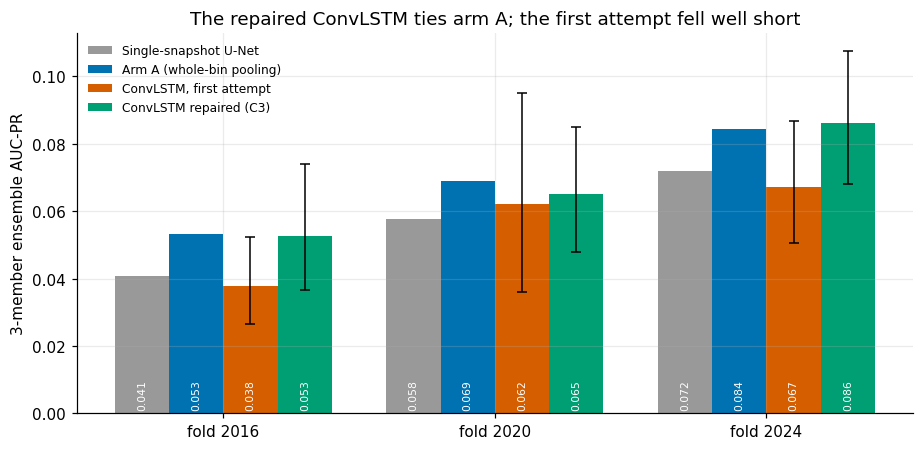

In [2]:
def fold_table(ev):
    return {f["year"]: f for f in ev["folds"]}
F1, F3 = fold_table(first), fold_table(c3)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
w = 0.2
x = np.arange(3)
series = [("baseline", [BASELINE[y] for y in FOLDS], None),
          ("A", [F3[y]["a_ens_ap"] for y in FOLDS], None),
          ("first", [F1[y]["convlstm_ens_ap"] for y in FOLDS], [F1[y]["convlstm_ens_ci95"] for y in FOLDS]),
          ("C3", [F3[y]["convlstm_ens_ap"] for y in FOLDS], [F3[y]["convlstm_ens_ci95"] for y in FOLDS])]
for i, (k, vals, ci) in enumerate(series):
    pos = x + (i - 1.5) * w
    ax.bar(pos, vals, w, color=COL[k], label=LAB[k])
    if ci:
        lo = np.clip(np.array(vals) - np.array([c[0] for c in ci]), 0, None); hi = np.clip(np.array([c[1] for c in ci]) - np.array(vals), 0, None)
        ax.errorbar(pos, vals, yerr=[lo, hi], fmt="none", ecolor="black", capsize=3, lw=1)
    for p, v in zip(pos, vals):
        ax.text(p, 0.001, f"{v:.3f}", ha="center", va="bottom", fontsize=7, color="white", rotation=90)
ax.set_xticks(x); ax.set_xticklabels([f"fold {y}" for y in FOLDS]); ax.set_ylabel("3-member ensemble AUC-PR")
ax.set_title("The repaired ConvLSTM ties arm A; the first attempt fell well short")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

## 2. Effect sizes against the decision rule

`E = ConvLSTM ensemble / arm A ensemble - 1` per fold, with the **paired** day-bootstrap 95% interval (the same resampled days for both arms, which is far tighter than comparing two independent intervals). The shaded band is the "no detectable effect" zone (|pooled E| < 8%).

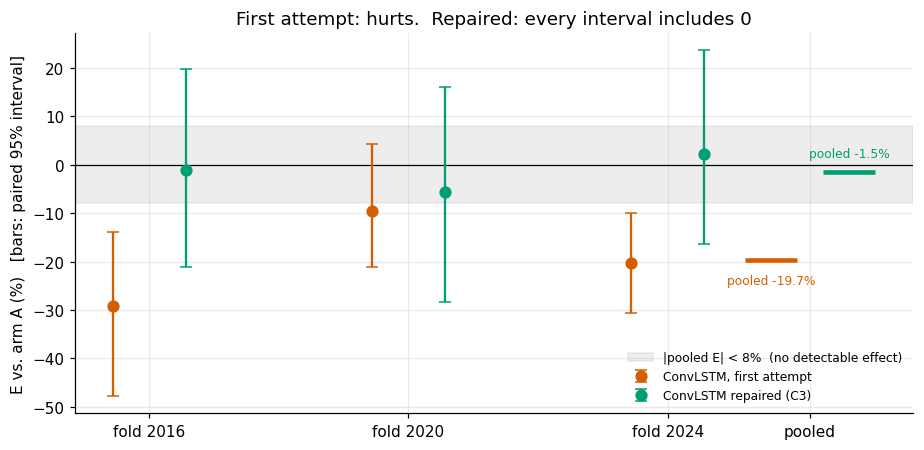

{'first': 'hurts', 'C3': 'no detectable effect'}


In [3]:
def eff(ev):
    rows = []
    for f in ev["folds"]:
        d = f["paired_diff_ci95"]; a = f["a_ens_ap"]
        rows.append((f["year"], f["E"], d[0] / a, d[1] / a))
    return rows

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.axhspan(-8, 8, color="#bbbbbb", alpha=0.25, label="|pooled E| < 8%  (no detectable effect)")
ax.axhline(0, color="black", lw=0.8)
for i, (k, ev) in enumerate([("first", first), ("C3", c3)]):
    rows = eff(ev)
    xs = np.arange(3) + (i - 0.5) * 0.28
    E = np.array([r[1] for r in rows]) * 100
    lo = E - np.array([r[2] for r in rows]) * 100; hi = np.array([r[3] for r in rows]) * 100 - E
    ax.errorbar(xs, E, yerr=[lo, hi], fmt="o", color=COL[k], capsize=4, label=f"{LAB[k]}", ms=7)
    pooled = ev["summary"]["pooled_E"] * 100
    ax.hlines(pooled, 2.55 + (i - 0.5) * 0.3 - 0.1, 2.55 + (i - 0.5) * 0.3 + 0.1, color=COL[k], lw=3)
    ax.text(2.55 + (i - 0.5) * 0.3, pooled + (3 if i else -5), f"pooled {pooled:+.1f}%", ha="center", fontsize=8, color=COL[k])
ax.set_xticks(list(range(3)) + [2.55]); ax.set_xticklabels([f"fold {y}" for y in FOLDS] + ["pooled"])
ax.set_ylabel("E vs. arm A (%)   [bars: paired 95% interval]")
ax.set_title("First attempt: hurts.  Repaired: every interval includes 0")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
print({k: ev["summary"]["verdict"] for k, ev in [("first", first), ("C3", c3)]})

## 3. Chapter 2: what was wrong with the first attempt

The first ConvLSTM trained, but fit the training years *worse* than arm A did, so it was not overfitting; it was a broken optimization. Inspecting the LSTM gates showed why. Pre-activations into the sigmoid/tanh gates should have a standard deviation of order 1. In the trained models they were **thousands to hundreds of thousands**, so almost every gate sat in its flat region and passed no gradient. The cause: the encoder's raw-scale activations (the inputs are un-normalized HRRR fields) fed the LSTM directly.

The repair ("C3") added a GroupNorm on the bottleneck before the LSTM, pooled skip connections (the learned analogue of arm A's time-mean/time-max), gradient clipping, and a lower learning rate (1e-4).

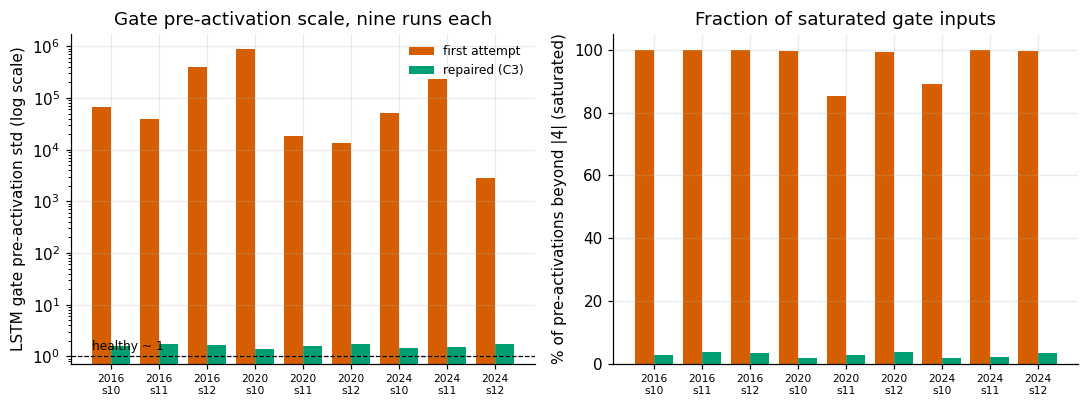

first attempt: preact std 2847 - 881299 | C3: 1.41 - 1.75


In [4]:
keys = sorted(gate_first)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
xs = np.arange(len(keys))
ax = axes[0]
ax.bar(xs - 0.2, [gate_first[k]["preact_std"] for k in keys], 0.4, color=COL["first"], label="first attempt")
ax.bar(xs + 0.2, [gate_c3[k]["preact_std"] for k in keys], 0.4, color=COL["C3"], label="repaired (C3)")
ax.set_yscale("log"); ax.axhline(1, color="black", lw=0.8, ls="--"); ax.text(-0.4, 1.3, "healthy ~ 1", ha="left", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels([k.replace("_s", "\ns") for k in keys], fontsize=7)
ax.set_ylabel("LSTM gate pre-activation std (log scale)"); ax.set_title("Gate pre-activation scale, nine runs each"); ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.bar(xs - 0.2, [gate_first[k]["frac_abs_gt4"] * 100 for k in keys], 0.4, color=COL["first"])
ax.bar(xs + 0.2, [gate_c3[k]["frac_abs_gt4"] * 100 for k in keys], 0.4, color=COL["C3"])
ax.set_xticks(xs); ax.set_xticklabels([k.replace("_s", "\ns") for k in keys], fontsize=7)
ax.set_ylabel("% of pre-activations beyond |4| (saturated)"); ax.set_title("Fraction of saturated gate inputs")
plt.tight_layout(); plt.show()
print("first attempt: preact std", f"{min(g['preact_std'] for g in gate_first.values()):.0f} - {max(g['preact_std'] for g in gate_first.values()):.0f}",
      "| C3:", f"{min(g['preact_std'] for g in gate_c3.values()):.2f} - {max(g['preact_std'] for g in gate_c3.values()):.2f}")

### The diagnostic ladder (exploratory, fold 2020, seeds 10-11, 10 epochs)

Before spending 28 hours on a full study, a cheap ladder of single-fold runs asked three questions. Held-out AUC-PR, plain weights. **These are single seeds with ~19-25% noise, so they chose what to test and prove nothing.**

* Can the repaired model learn at all? (memorize 20 runs): yes, train AUC-PR ~1.0, better than a U-Net.
* Was lr 1e-3 too aggressive? Yes: lr 1e-4 lifted C3 from 0.065 to 0.069 / 0.082.
* Is that just the learning rate? A matched U-Net at lr 1e-4 scored 0.049 / 0.061, below C3's 0.069 / 0.082, so there was a gap worth a full study.
* Does recurrence matter? A C3 with the LSTM replaced by a per-hour 1x1 conv scored the same (0.066).

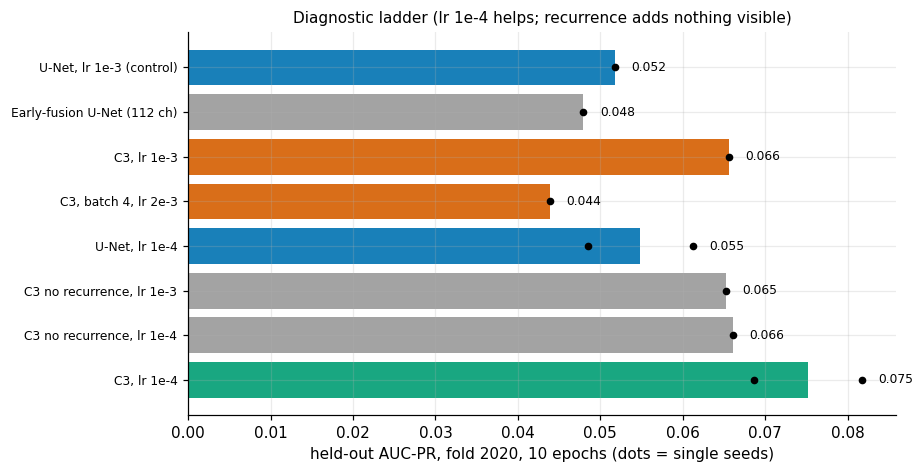

In [5]:
L = M / "convlstm/diagnostics/ladder"
lad = lambda n: load(L / f"{n}.json")["variants"]["plain"]["heldout_auc_pr"]
unet = [load(L / f"unet_lr1e4_s{s}/results.json")["summary"]["auc_pr_mean"] for s in (10, 11)]
rows = [
    ("U-Net, lr 1e-3 (control)",           [0.0518], "A"),
    ("Early-fusion U-Net (112 ch)",        [lad("early_fusion")], "baseline"),
    ("C3, lr 1e-3",                        [0.0656], "first"),
    ("C3, batch 4, lr 2e-3",               [lad("c3_b4_lr2e3")], "first"),
    ("U-Net, lr 1e-4",                     unet, "A"),
    ("C3 no recurrence, lr 1e-3",          [lad("c3_norecur")], "baseline"),
    ("C3 no recurrence, lr 1e-4",          [lad("c3_norecur_lr1e4")], "baseline"),
    ("C3, lr 1e-4",                        [lad("c3_lr1e4"), lad("c3_lr1e4_s11")], "C3"),
]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for i, (name, vals, k) in enumerate(rows):
    ax.barh(i, np.mean(vals), color=COL[k], alpha=0.9)
    for v in vals:
        ax.plot(v, i, "o", color="black", ms=4)
    ax.text(max(vals) + 0.002, i, f"{np.mean(vals):.3f}", va="center", fontsize=8)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows], fontsize=8); ax.invert_yaxis()
ax.set_xlabel("held-out AUC-PR, fold 2020, 10 epochs (dots = single seeds)")
ax.set_title("Diagnostic ladder (lr 1e-4 helps; recurrence adds nothing visible)", fontsize=10)
plt.tight_layout(); plt.show()

## 4. Chapter 3-4: the repaired model ties arm A, for an interesting reason

Individual repaired models are clearly **weaker** than arm A's (about -24 to -31% on average), yet their three-member ensembles tie A's. The ensemble gain over the average single seed is **+51-67% for C3 versus +15% for A**. C3's members are individually worse and much more different from one another.

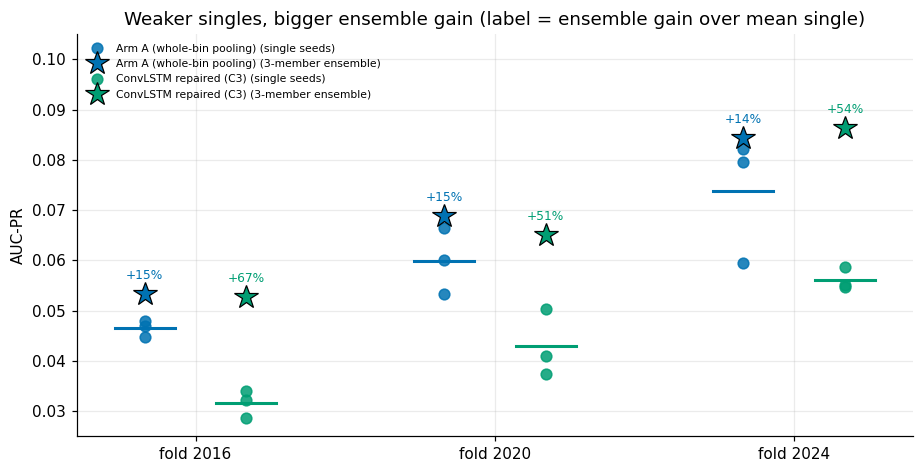

In [6]:
def singles(ev, key):
    return {f["year"]: [f[key][str(s)] for s in SEEDS] for f in ev["folds"]}
c3s, as_ = singles(c3, "convlstm_single_aps"), singles(c3, "a_single_aps")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for j, y in enumerate(FOLDS):
    for off, k, vals, ens in [(-0.17, "A", as_[y], F3[y]["a_ens_ap"]), (0.17, "C3", c3s[y], F3[y]["convlstm_ens_ap"])]:
        ax.plot([j + off] * 3, vals, "o", color=COL[k], ms=7, alpha=0.85, label=f"{LAB[k]} (single seeds)" if j == 0 else None)
        ax.plot([j + off - 0.1, j + off + 0.1], [np.mean(vals)] * 2, color=COL[k], lw=2)
        ax.plot(j + off, ens, "*", color=COL[k], ms=16, mec="black", mew=0.8, label=f"{LAB[k]} (3-member ensemble)" if j == 0 else None)
        g = ens / np.mean(vals) - 1
        ax.text(j + off, ens + 0.003, f"+{g*100:.0f}%", ha="center", fontsize=8, color=COL[k])
ax.set_xticks(range(3)); ax.set_xticklabels([f"fold {y}" for y in FOLDS]); ax.set_ylabel("AUC-PR")
ax.set_title("Weaker singles, bigger ensemble gain (label = ensemble gain over mean single)")
ax.set_ylim(0.025, 0.105); ax.legend(frameon=False, fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

### The other half: C3 overfits

Arm A's validation loss stays at or below its training loss. C3's final validation loss is **2.3-4.3x** its training loss in all nine runs (pre-registered healthy band: 0.4-1.3), and its training loss is about a third of A's. The model fits the training years far better than the held-out year. The first attempt underfit; the repaired model overfits.

9 C3 runs, 9 arm A runs loaded


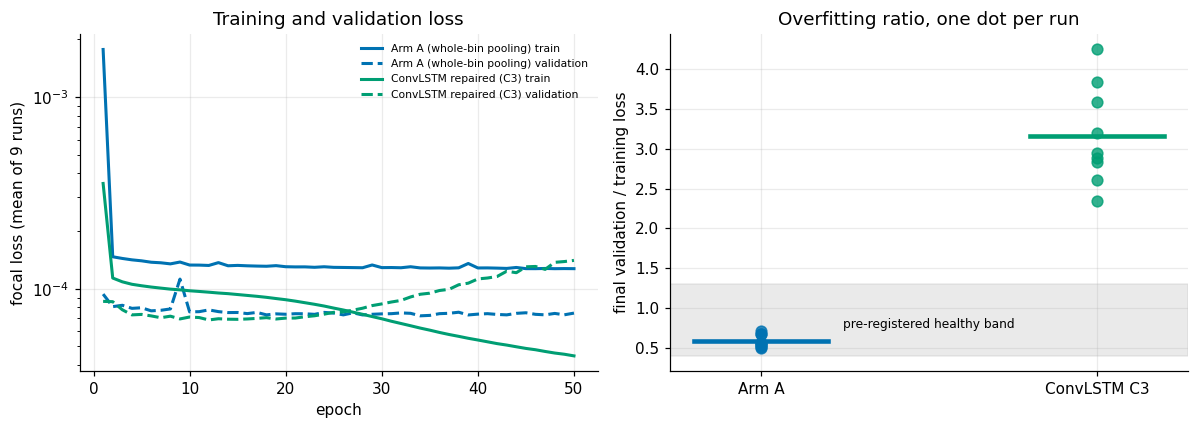

In [7]:
def curves(pattern):
    out = {}
    for p in sorted(glob.glob(str(pattern))):
        if "ema" in p:
            continue
        ck = torch.load(p, map_location="cpu", weights_only=False)
        out[p] = (np.array(ck["loss_history"]), np.array(ck["val_loss_history"]))
    return out
c3c = curves(M / "convlstm/full_study_c3/seed*/fold*/convlstm_heldout_*_s*.pt")
c3c = {p: v for p, v in c3c.items() if "ema" not in p}
ac = curves(M / "hourly_study/wholebin/seed*/tornado_unet_heldout_*.pt")
ac = {p: v for p, v in ac.items() if "ema" not in p}
print(len(c3c), "C3 runs,", len(ac), "arm A runs loaded")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
for name, d, k in [("A", ac, "A"), ("C3", c3c, "C3")]:
    tr = np.mean([v[0] for v in d.values()], axis=0); va = np.mean([v[1] for v in d.values()], axis=0)
    e = np.arange(1, len(tr) + 1)
    ax.plot(e, tr, color=COL[k], lw=2, label=f"{LAB[k]} train"); ax.plot(e, va, color=COL[k], lw=2, ls="--", label=f"{LAB[k]} validation")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("focal loss (mean of 9 runs)"); ax.set_title("Training and validation loss"); ax.legend(frameon=False, fontsize=7)
ax = axes[1]
ratio = lambda d: [v[1][-1] / v[0][-1] for v in d.values()]
for i, (d, k) in enumerate([(ac, "A"), (c3c, "C3")]):
    r = ratio(d)
    ax.plot([i] * len(r), r, "o", color=COL[k], ms=7, alpha=0.8)
    ax.plot([i - 0.2, i + 0.2], [np.mean(r)] * 2, color=COL[k], lw=3)
ax.axhspan(0.4, 1.3, color="#bbbbbb", alpha=0.3); ax.text(0.5, 0.75, "pre-registered healthy band", ha="center", fontsize=8)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Arm A", "ConvLSTM C3"]); ax.set_ylabel("final validation / training loss"); ax.set_title("Overfitting ratio, one dot per run")
plt.tight_layout(); plt.show()

## 5. Secondary metrics: where the ConvLSTM is different

Descriptive only, no decision rule. The ConvLSTM's clear strength is the **timing** problem arm A struggled with: false alarms on the *quiet bins of days that did have a tornado* (the model knows it is a severe day; the question is *when*). C3 cuts that false-alarm rate by 45-63% at 50% recall and raises map-level AUC-ROC in every fold. But cell-level ranking is worse (cell AUC-ROC lower, Cohen's d roughly halved) and bin-1 AUC-PR does not improve.

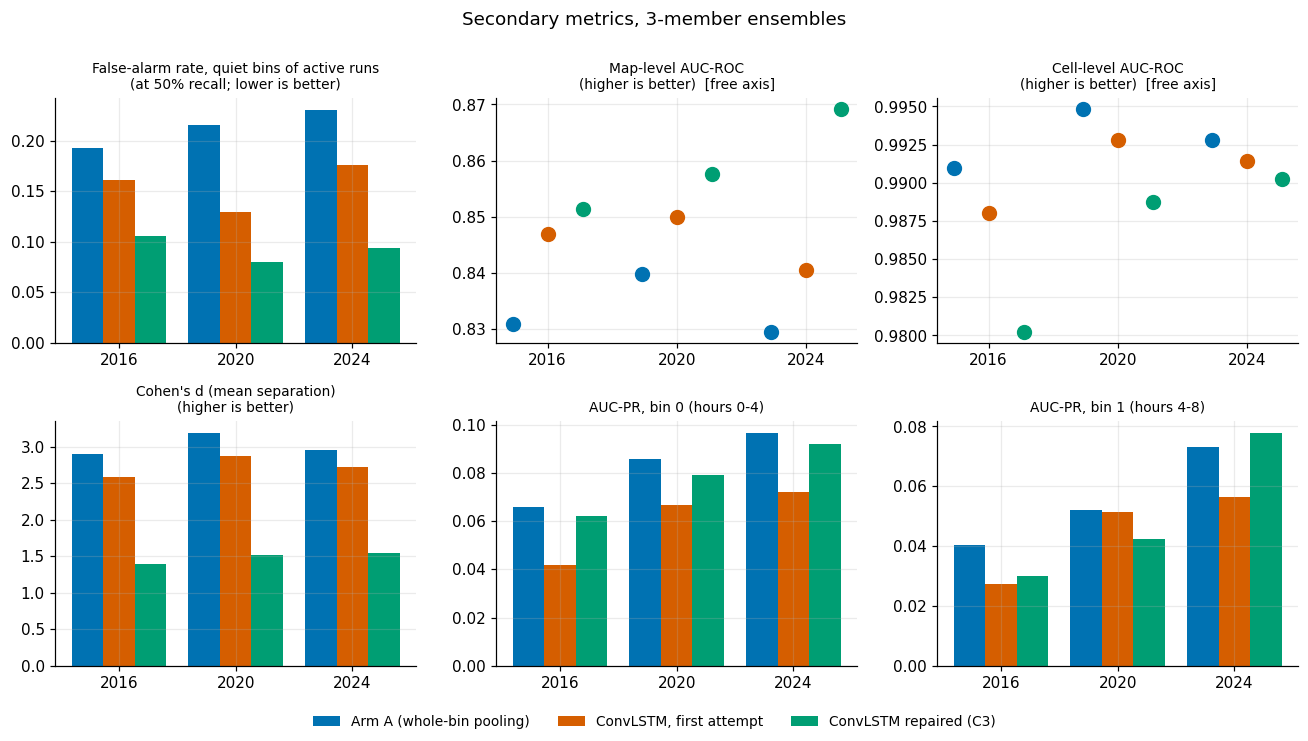

2016 timing false-alarm rate A 0.193 -> C3 0.106  (-45%)
2020 timing false-alarm rate A 0.216 -> C3 0.080  (-63%)
2024 timing false-alarm rate A 0.231 -> C3 0.093  (-60%)


In [8]:
metrics = [("far_quiet_bins_of_active_runs@recall0.5", "False-alarm rate, quiet bins of active runs\n(at 50% recall; lower is better)"),
           ("map_auc_roc", "Map-level AUC-ROC\n(higher is better)"),
           ("auc_roc", "Cell-level AUC-ROC\n(higher is better)"),
           ("cohens_d", "Cohen's d (mean separation)\n(higher is better)"),
           ("auc_pr_bin0", "AUC-PR, bin 0 (hours 0-4)"),
           ("auc_pr_bin1", "AUC-PR, bin 1 (hours 4-8)")]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.6))
dot_metrics = {"map_auc_roc", "auc_roc"}   # values all near 0.8-1.0: dots on a free axis, not bars from zero
for ax, (m, title) in zip(axes.ravel(), metrics):
    for i, (k, vals) in enumerate([("A", [F3[y]["a_ens_metrics"][m] for y in FOLDS]),
                                   ("first", [F1[y]["convlstm_ens_metrics"][m] for y in FOLDS]),
                                   ("C3", [F3[y]["convlstm_ens_metrics"][m] for y in FOLDS])]):
        pos = np.arange(3) + (i - 1) * 0.27
        if m in dot_metrics:
            ax.plot(pos, vals, "o", color=COL[k], ms=9, label=LAB[k])
        else:
            ax.bar(pos, vals, 0.27, color=COL[k], label=LAB[k])
    ax.set_xticks(range(3)); ax.set_xticklabels(FOLDS); ax.set_title(title + ("  [free axis]" if m in dot_metrics else ""), fontsize=9)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=9)
plt.suptitle("Secondary metrics, 3-member ensembles", y=1.0); plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()
for m, _ in metrics[:1]:
    for y in FOLDS:
        a, c = F3[y]["a_ens_metrics"][m], F3[y]["convlstm_ens_metrics"][m]
        print(y, f"timing false-alarm rate A {a:.3f} -> C3 {c:.3f}  ({(c/a-1)*100:+.0f}%)")

### Control U-Net vs. repaired ConvLSTM: precision, recall, AUC-ROC and AUC-PR

Just the two arms, per held-out year. **These are final-model values, not per-epoch curves:** each run computed its test metrics once, on the trained model (the full study recorded only per-epoch *loss*; the per-epoch held-out curves come from a separate one-fold rerun, in the next subsection). Bars are the 3-member ensemble; dots are the three single seeds (EMA weights).
Precision and recall are at each model's own best-F1 threshold (the threshold maximizing F1 on the test year), so they describe one operating point, not the whole curve. AUC-ROC sits near 0.99 for both because of the extreme class imbalance and is the least informative of the four.

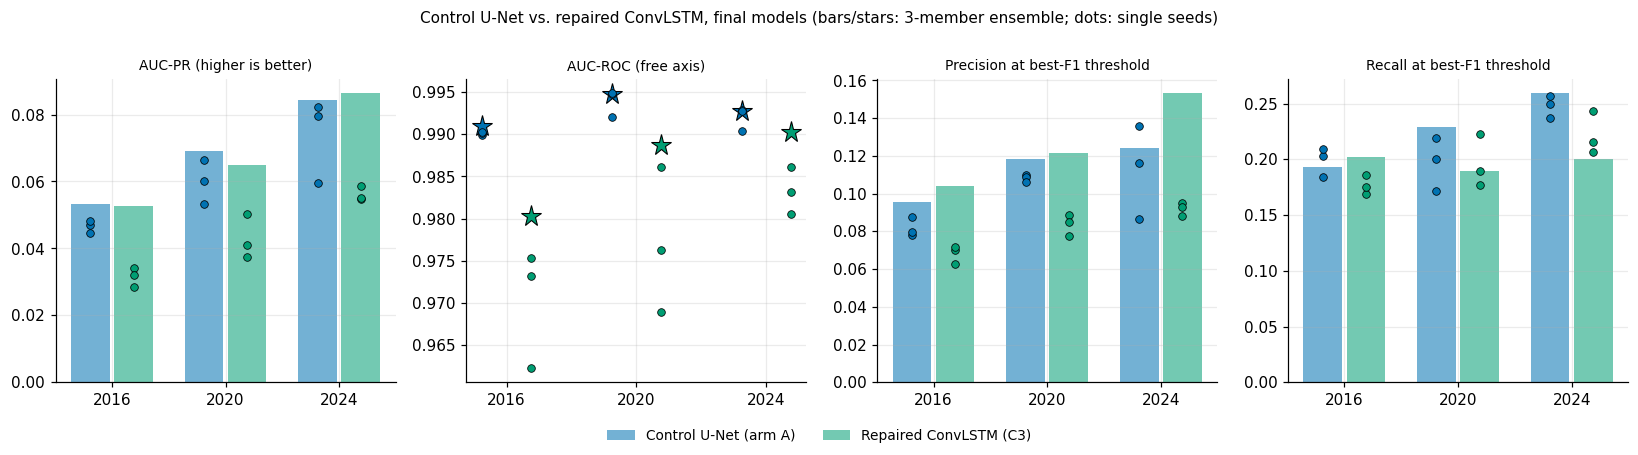

auc_pr     ensemble A / C3 by year: [(0.0534, 0.0528), (0.069, 0.065), (0.0845, 0.0863)]
auc_roc    ensemble A / C3 by year: [(0.991, 0.9803), (0.9948, 0.9887), (0.9928, 0.9903)]
precision  ensemble A / C3 by year: [(0.0957, 0.1039), (0.1183, 0.1217), (0.124, 0.1531)]
recall     ensemble A / C3 by year: [(0.1928, 0.2021), (0.2286, 0.1896), (0.2591, 0.2)]


In [9]:
def single_metrics():
    A = {y: [] for y in FOLDS}; C = {y: [] for y in FOLDS}
    for s in SEEDS:
        for f in load(M / f"hourly_study/wholebin/seed{s}/results.json")["folds"]:
            m = f["ema_metrics"]["0.9999"]; A[f["held_out_year"]].append({"auc_pr": m["auc_pr"], "auc_roc": m["auc_roc"], "precision": m["precision_at_best_f1"], "recall": m["recall_at_best_f1"]})
        for y in FOLDS:
            m = load(M / f"convlstm/full_study_c3/seed{s}/fold{y}/results.json")["metrics"]["ema0.9999"]
            C[y].append({"auc_pr": m["auc_pr"], "auc_roc": m["auc_roc"], "precision": m["precision_at_best_f1"], "recall": m["recall_at_best_f1"]})
    return A, C
SA, SC = single_metrics()
panels = [("auc_pr", "AUC-PR (higher is better)"), ("auc_roc", "AUC-ROC (free axis)"), ("precision", "Precision at best-F1 threshold"), ("recall", "Recall at best-F1 threshold")]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (m, title) in zip(axes, panels):
    for i, (k, ens, sing) in enumerate([("A", {y: F3[y]["a_ens_metrics"][m] for y in FOLDS}, SA), ("C3", {y: F3[y]["convlstm_ens_metrics"][m] for y in FOLDS}, SC)]):
        pos = np.arange(3) + (i - 0.5) * 0.38
        if m == "auc_roc":
            ax.plot(pos, [ens[y] for y in FOLDS], "*", color=COL[k], ms=14, mec="black", mew=0.7, label="Control U-Net (arm A)" if k == "A" else "Repaired ConvLSTM (C3)")
        else:
            ax.bar(pos, [ens[y] for y in FOLDS], 0.34, color=COL[k], alpha=0.55, label="Control U-Net (arm A)" if k == "A" else "Repaired ConvLSTM (C3)")
        for j, y in enumerate(FOLDS):
            ax.plot([pos[j]] * len(sing[y]), [d[m] for d in sing[y]], "o", color=COL[k], ms=5, mec="black", mew=0.5)
    ax.set_xticks(range(3)); ax.set_xticklabels(FOLDS); ax.set_title(title, fontsize=9)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=9)
plt.suptitle("Control U-Net vs. repaired ConvLSTM, final models (bars/stars: 3-member ensemble; dots: single seeds)", y=1.0, fontsize=10)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()
for m, _ in panels:
    print(f"{m:10s} ensemble A / C3 by year:", [(round(F3[y]['a_ens_metrics'][m], 4), round(F3[y]['convlstm_ens_metrics'][m], 4)) for y in FOLDS])

### Per-epoch held-out metrics: a one-fold rerun (fold 2020, seed 10)

The full study logged only loss per epoch. This subsection reruns **one fold and one seed of each arm** (identical recipe and seed to the full-study run; the final-epoch numbers reproduce it exactly, 0.0664 and 0.0374) with the held-out metrics computed after every epoch, on both the raw and the EMA weights. Pre-stated predictions and scoring: `docs/convlstm_per_epoch_plan.md`.

**Reading it.** One run per arm, so single-seed noise (about 19-25%) applies to every wiggle. The EMA curves (solid) start near zero because the average begins at the random initial weights and needs a few epochs to catch up; that ramp is not a training failure. **Caveat:** the held-out year here is the year being scored, so picking an epoch from these curves is selecting on the test data. They show how training behaves; a fair early-stopping rule needs its own validation set.

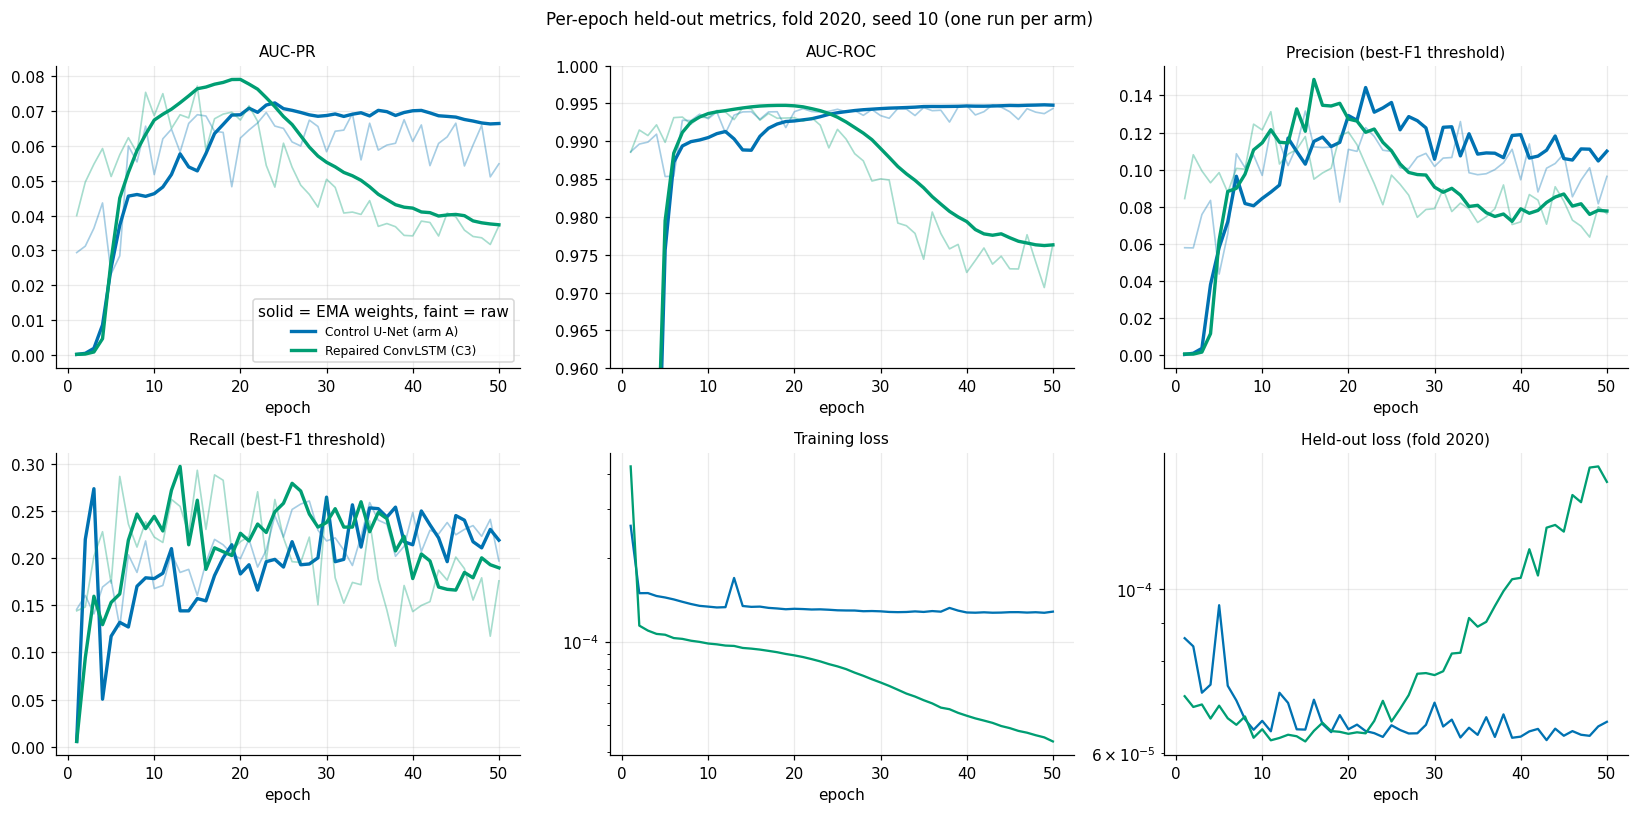

A   raw        peak AUC-PR 0.0696 at epoch 23 | epoch 50 0.0549 (0.79 of peak)
A   ema0.9999  peak AUC-PR 0.0723 at epoch 24 | epoch 50 0.0664 (0.92 of peak)
A   held-out loss minimum at epoch 43, epoch-50 value 6.62e-05
C3  raw        peak AUC-PR 0.0772 at epoch 15 | epoch 50 0.0371 (0.48 of peak)
C3  ema0.9999  peak AUC-PR 0.0791 at epoch 20 | epoch 50 0.0374 (0.47 of peak)
C3  held-out loss minimum at epoch 15, epoch-50 value 1.40e-04


In [10]:
PE = {"A": M / "convlstm/per_epoch/arm_a/results.json", "C3": M / "convlstm/per_epoch/c3/results.json"}
if all(p.exists() for p in PE.values()):
    def find(o, key):
        if isinstance(o, dict):
            for k, v in o.items():
                if k == key: return v
                r = find(v, key)
                if r is not None: return r
        if isinstance(o, list):
            for v in o:
                r = find(v, key)
                if r is not None: return r
    R = {k: json.load(open(p)) for k, p in PE.items()}
    E = {k: find(r, "epoch_metrics") for k, r in R.items()}
    TR = {k: find(r, "loss_history") for k, r in R.items()}
    VA = {k: find(r, "val_loss_history") for k, r in R.items()}
    x = np.arange(1, 51)
    names = {"A": "Control U-Net (arm A)", "C3": "Repaired ConvLSTM (C3)"}
    pp = [("auc_pr", "AUC-PR"), ("auc_roc", "AUC-ROC"), ("precision_at_best_f1", "Precision (best-F1 threshold)"), ("recall_at_best_f1", "Recall (best-F1 threshold)")]
    fig, ax = plt.subplots(2, 3, figsize=(15, 7.5)); ax = ax.ravel()
    for i, (k, t) in enumerate(pp):
        for a in ("A", "C3"):
            ax[i].plot(x, [m[k] for m in E[a]["raw"]], color=COL[a], alpha=0.35, lw=1.1)
            ax[i].plot(x, [m[k] for m in E[a]["ema0.9999"]], color=COL[a], lw=2.2, label=names[a])
        ax[i].set_title(t, fontsize=10); ax[i].set_xlabel("epoch")
        if k == "auc_roc": ax[i].set_ylim(0.96, 1.0)
    ax[0].legend(title="solid = EMA weights, faint = raw", fontsize=8)
    for a in ("A", "C3"):
        ax[4].plot(x, TR[a], color=COL[a], label=names[a]); ax[5].plot(x, VA[a], color=COL[a], label=names[a])
    ax[4].set_title("Training loss", fontsize=10); ax[5].set_title("Held-out loss (fold 2020)", fontsize=10)
    for a_ in ax[4:]: a_.set_yscale("log"); a_.set_xlabel("epoch")
    plt.suptitle("Per-epoch held-out metrics, fold 2020, seed 10 (one run per arm)", fontsize=11)
    plt.tight_layout(); plt.show()
    for a in ("A", "C3"):
        for w in ("raw", "ema0.9999"):
            ap = np.array([m["auc_pr"] for m in E[a][w]])
            print(f"{a:3s} {w:10s} peak AUC-PR {ap.max():.4f} at epoch {ap.argmax()+1:2d} | epoch 50 {ap[-1]:.4f} ({ap[-1]/ap.max():.2f} of peak)")
        print(f"{a:3s} held-out loss minimum at epoch {int(np.argmin(VA[a]))+1}, epoch-50 value {VA[a][-1]:.2e}")
else:
    print("per-epoch rerun not found; run scripts/11_convlstm/run_per_epoch_study.sh")

**What the curves show.** Arm A's AUC-PR rises until about epoch 20, then holds (epoch 50 is 0.92 of its EMA peak); its AUC-ROC never degrades. The ConvLSTM peaks earlier and higher (EMA 0.0791 at epoch 20, vs. A's 0.0723 at epoch 24) and then **loses about half of it** by epoch 50 as its cell AUC-ROC falls from 0.995 to 0.976 and its held-out loss climbs to about double its minimum, while training loss keeps falling. So the 50-epoch "tie" in the study compares A near its best with the ConvLSTM well past its best. The peak-to-peak gap (+9%) is one seed each and inside the noise, and the best epoch is chosen on the test year, so it is optimistic. A fair test needs early stopping on a separate validation set (next steps).

## 6. Chapter 5: can dropout fix the overfitting?

Dropout is the obvious regularizer (and worked in a sibling project). Implementation: channel-wise `Dropout2d` on the LSTM's input and on the hidden state handed to the decoder; zero parameters, off in eval mode, and p=0 reproduces C3 exactly (tested).

**Two-stage design, pre-registered before anything ran** (`docs/convlstm_dropout_preregistration.md`):
* **Stage 1 (rate selection):** a *different* fold (2018) and *different* seeds (20, 21) from the confirmatory study, so choosing the rate cannot leak into it. Rates 0.0 (control), 0.1, 0.3, 0.5.
* **Stage 2 (confirmation):** the chosen rate on the same nine runs as C3 (folds 2016/2020/2024, seeds 10-12), judged by the same rule against arm A.

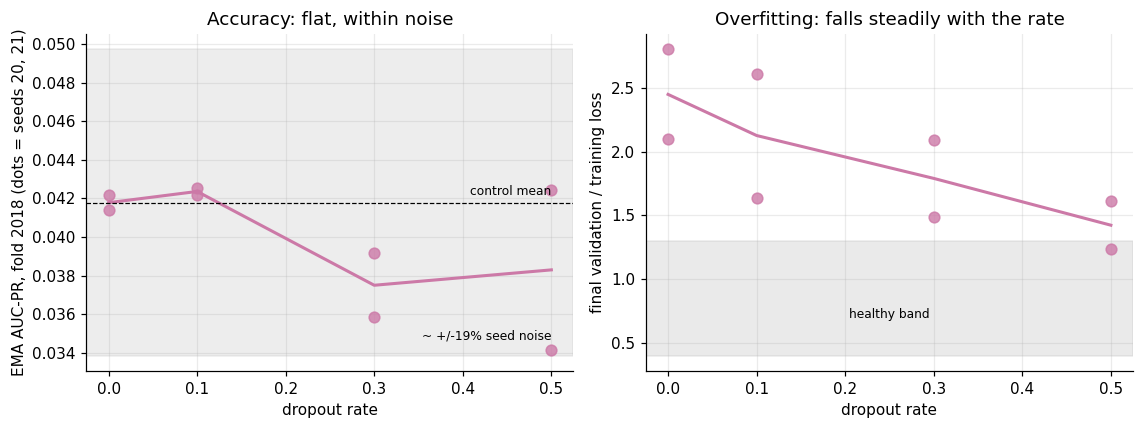

rule outcome: {'best_rate': 0.1, 'proceed_to_stage2': True, 'gain_vs_control': 0.013926602329885185}


In [11]:
sel = load(M / "convlstm/dropout_select/selection.json")
rows = sel["rows"]; rates = sorted(float(k) for k in rows)
get = lambda p, f: rows[str(p) if str(p) in rows else f"{p}"][f]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
ax = axes[0]
for p in rates:
    v = get(p, "auc_pr"); ax.plot([p] * len(v), v, "o", color=COL["drop"], ms=7, alpha=0.8)
ax.plot(rates, [np.mean(get(p, "auc_pr")) for p in rates], "-", color=COL["drop"], lw=2)
ctrl = np.mean(get(0.0, "auc_pr")); ax.axhline(ctrl, color="black", lw=0.8, ls="--"); ax.text(0.5, ctrl * 1.01, "control mean", ha="right", fontsize=8)
ax.axhspan(ctrl * 0.81, ctrl * 1.19, color="#bbbbbb", alpha=0.25); ax.text(0.5, ctrl * 0.83, "~ +/-19% seed noise", ha="right", fontsize=8)
ax.set_xlabel("dropout rate"); ax.set_ylabel("EMA AUC-PR, fold 2018 (dots = seeds 20, 21)"); ax.set_title("Accuracy: flat, within noise")
ax = axes[1]
for p in rates:
    v = get(p, "ratio"); ax.plot([p] * len(v), v, "o", color=COL["drop"], ms=7, alpha=0.8)
ax.plot(rates, [np.mean(get(p, "ratio")) for p in rates], "-", color=COL["drop"], lw=2)
ax.axhspan(0.4, 1.3, color="#bbbbbb", alpha=0.3); ax.text(0.25, 0.7, "healthy band", ha="center", fontsize=8)
ax.set_xlabel("dropout rate"); ax.set_ylabel("final validation / training loss"); ax.set_title("Overfitting: falls steadily with the rate")
plt.tight_layout(); plt.show()
print("rule outcome:", {k: v for k, v in sel.items() if k != "rows"})

**Stage 1 reading.** Dropout does exactly what it is supposed to on the overfitting ratio (2.45 -> 1.42 from p=0 to p=0.5) but AUC-PR does not move: +1.4% at p=0.1 (nothing) and slightly lower at 0.3 and 0.5, all far inside the ~19% seed noise. The pre-registered rule picks p=0.1, but only because it ties the control while having a lower ratio; it is not evidence that dropout helps. Predictions scored: the best rate did **not** beat the control by 10% (I gave that 40%) and did **not** bring the ratio below 1.5.

### Stage 2: confirmatory study

In [12]:
S2 = M / "convlstm/full_study_c3_dropout"
s2_eval = S2 / "convlstm_eval.json"
done = sorted(glob.glob(str(S2 / "seed*/fold*/results.json")))
print(f"Stage 2 runs finished: {len(done)} / 9")
HAVE_S2 = s2_eval.exists()
if HAVE_S2:
    s2 = load(s2_eval); F4 = fold_table(s2)
    print("Stage 2 verdict:", s2["summary"]["verdict"], "| pooled E:", f"{s2['summary']['pooled_E']*100:+.1f}%")
else:
    print("Stage 2 evaluation not available yet; the figures below appear once it is run.")

Stage 2 runs finished: 9 / 9
Stage 2 verdict: no detectable effect | pooled E: +1.9%


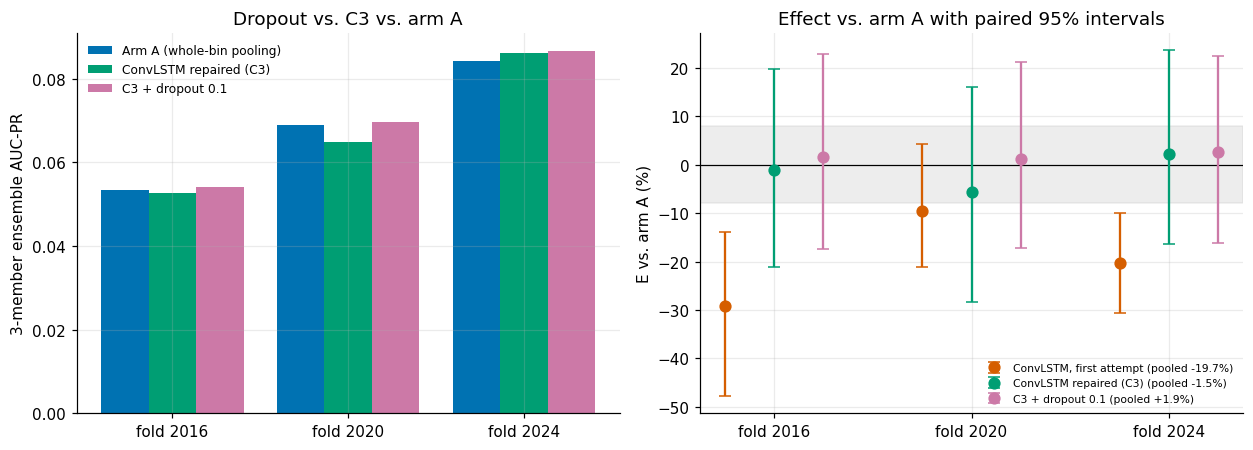

In [13]:
if HAVE_S2:
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    ax = axes[0]
    for i, (k, d) in enumerate([("A", F3), ("C3", F3), ("drop", F4)]):
        vals = [d[y]["a_ens_ap"] if k == "A" else d[y]["convlstm_ens_ap"] for y in FOLDS]
        ax.bar(np.arange(3) + (i - 1) * 0.27, vals, 0.27, color=COL[k], label=LAB[k])
    ax.set_xticks(range(3)); ax.set_xticklabels([f"fold {y}" for y in FOLDS]); ax.set_ylabel("3-member ensemble AUC-PR"); ax.set_title("Dropout vs. C3 vs. arm A"); ax.legend(frameon=False, fontsize=8)
    ax = axes[1]
    ax.axhspan(-8, 8, color="#bbbbbb", alpha=0.25); ax.axhline(0, color="black", lw=0.8)
    for i, (k, ev) in enumerate([("first", first), ("C3", c3), ("drop", s2)]):
        rows = eff(ev); xs = np.arange(3) + (i - 1) * 0.25
        E = np.array([r[1] for r in rows]) * 100
        lo = E - np.array([r[2] for r in rows]) * 100; hi = np.array([r[3] for r in rows]) * 100 - E
        ax.errorbar(xs, E, yerr=[lo, hi], fmt="o", color=COL[k], capsize=4, ms=7, label=f"{LAB[k]} (pooled {ev['summary']['pooled_E']*100:+.1f}%)")
    ax.set_xticks(range(3)); ax.set_xticklabels([f"fold {y}" for y in FOLDS]); ax.set_ylabel("E vs. arm A (%)"); ax.set_title("Effect vs. arm A with paired 95% intervals"); ax.legend(frameon=False, fontsize=7, loc="lower right")
    plt.tight_layout(); plt.show()
else:
    print("(pending)")

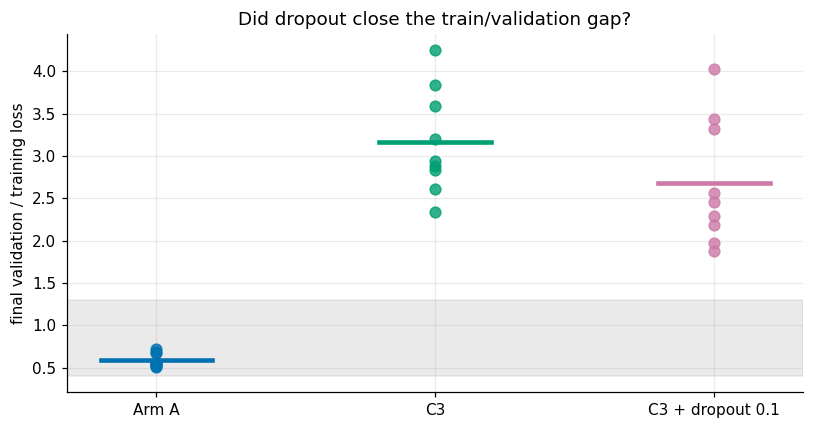

In [14]:
if HAVE_S2:
    dc = curves(M / "convlstm/full_study_c3_dropout/seed*/fold*/convlstm_heldout_*_s*.pt"); dc = {p: v for p, v in dc.items() if "ema" not in p}
    fig, ax = plt.subplots(figsize=(7.5, 4))
    for i, (name, d, k) in enumerate([("Arm A", ac, "A"), ("C3", c3c, "C3"), ("C3 + dropout 0.1", dc, "drop")]):
        r = [v[1][-1] / v[0][-1] for v in d.values()]
        ax.plot([i] * len(r), r, "o", color=COL[k], ms=7, alpha=0.8); ax.plot([i - 0.2, i + 0.2], [np.mean(r)] * 2, color=COL[k], lw=3)
    ax.axhspan(0.4, 1.3, color="#bbbbbb", alpha=0.3)
    ax.set_xticks(range(3)); ax.set_xticklabels(["Arm A", "C3", "C3 + dropout 0.1"]); ax.set_ylabel("final validation / training loss"); ax.set_title("Did dropout close the train/validation gap?")
    plt.tight_layout(); plt.show()
else:
    print("(pending)")

**Stage 2 reading.** All three arms sit within each other's intervals; dropout moves the ConvLSTM from "slightly below A" to "slightly above A" without leaving the noise. The overfitting ratio drops a little but stays far from arm A's.

## 6b. Chapter 6: early stopping on a validation set, for both arms

The per-epoch rerun showed the ConvLSTM peaking around epoch 20 and then overfitting, while arm A stays flat. This study gives **both arms** the same early-stopping rule (pre-registered, `docs/convlstm_early_stopping_preregistration.md`): stop when the validation AUC-PR of the EMA weights has not improved for 8 epochs (at least 10 epochs, cap 50), then restore the best epoch's weights.
The validation set is a mod-20 date split carved from the **training years**, so the test year is scored exactly once on the restored weights. Both arms therefore train on ~78% of the earlier runs, and E is measured against the **new early-stopped A**, not the old 50-epoch A.
Folds 2016 / 2020 / 2024, seeds 10-12; repaired C3 without dropout. Numbers: `models/convlstm/early_stop/`.

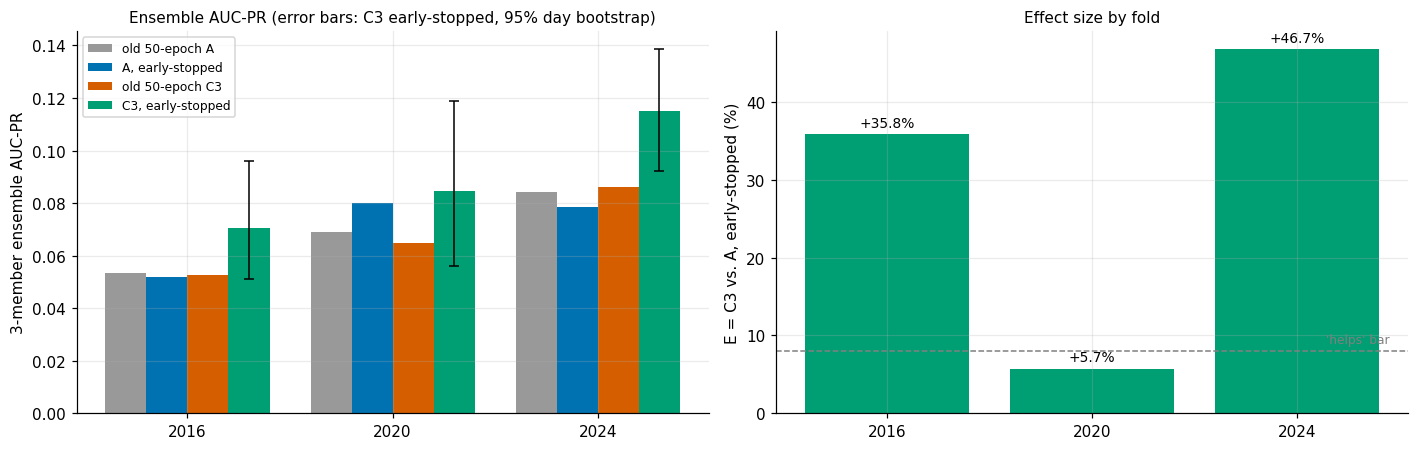

verdict: helps | pooled E +29.4% | folds positive 3/3 | paired interval excludes 0 in 2 | confirmed=True


In [15]:
ES = M / "convlstm/early_stop"
es_eval = load(ES / "c3/convlstm_eval.json")
def find(o, key):
    if isinstance(o, dict):
        if key in o: return o[key]
        for v in o.values():
            r = find(v, key)
            if r is not None: return r
    if isinstance(o, list):
        for v in o:
            r = find(v, key)
            if r is not None: return r
ES_A = {s: load(ES / f"arm_a/seed{s}/results.json")["folds"] for s in SEEDS}
ES_C = {(s, f): load(ES / f"c3/seed{s}/fold{f}/results.json") for s in SEEDS for f in FOLDS}
old_a = {2016: 0.0533, 2020: 0.0689, 2024: 0.0844}  # old 50-epoch arm A ensembles (hourly-features study)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(3); w = 0.2
rows = es_eval["folds"]
bars = [("old 50-epoch A", [old_a[f] for f in FOLDS], COL["baseline"]), ("A, early-stopped", [r["a_ens_ap"] for r in rows], COL["A"]),
        ("old 50-epoch C3", [c3["folds"][i]["convlstm_ens_ap"] for i in range(3)], COL["first"]), ("C3, early-stopped", [r["convlstm_ens_ap"] for r in rows], COL["C3"])]
for j, (lab, v, c) in enumerate(bars):
    ax[0].bar(x + (j - 1.5) * w, v, w, color=c, label=lab)
ci = np.array([r["convlstm_ens_ci95"] for r in rows])
ax[0].errorbar(x + 1.5 * w, [r["convlstm_ens_ap"] for r in rows], yerr=[[r["convlstm_ens_ap"] - c[0] for r, c in zip(rows, ci)], [c[1] - r["convlstm_ens_ap"] for r, c in zip(rows, ci)]], fmt="none", ecolor="black", capsize=3, lw=1)
ax[0].set_xticks(x); ax[0].set_xticklabels(FOLDS); ax[0].set_ylabel("3-member ensemble AUC-PR"); ax[0].legend(fontsize=8); ax[0].set_title("Ensemble AUC-PR (error bars: C3 early-stopped, 95% day bootstrap)", fontsize=10)
ax[1].bar(x, [100 * r["E"] for r in rows], color=COL["C3"])
for i, r in enumerate(rows):
    ax[1].text(i, 100 * r["E"] + 1, f"{100 * r['E']:+.1f}%", ha="center", fontsize=9)
ax[1].axhline(8, color="grey", ls="--", lw=1); ax[1].text(2.45, 9, "'helps' bar", fontsize=8, ha="right", color="grey")
ax[1].set_xticks(x); ax[1].set_xticklabels(FOLDS); ax[1].set_ylabel("E = C3 vs. A, early-stopped (%)"); ax[1].set_title("Effect size by fold", fontsize=10)
plt.tight_layout(); plt.show()
sm = es_eval["summary"]
print(f"verdict: {sm['verdict']} | pooled E {100 * sm['pooled_E']:+.1f}% | folds positive {sm['folds_positive']}/3 | paired interval excludes 0 in {sm['folds_paired_ci_excludes_zero']} | confirmed={sm['confirmed']}")

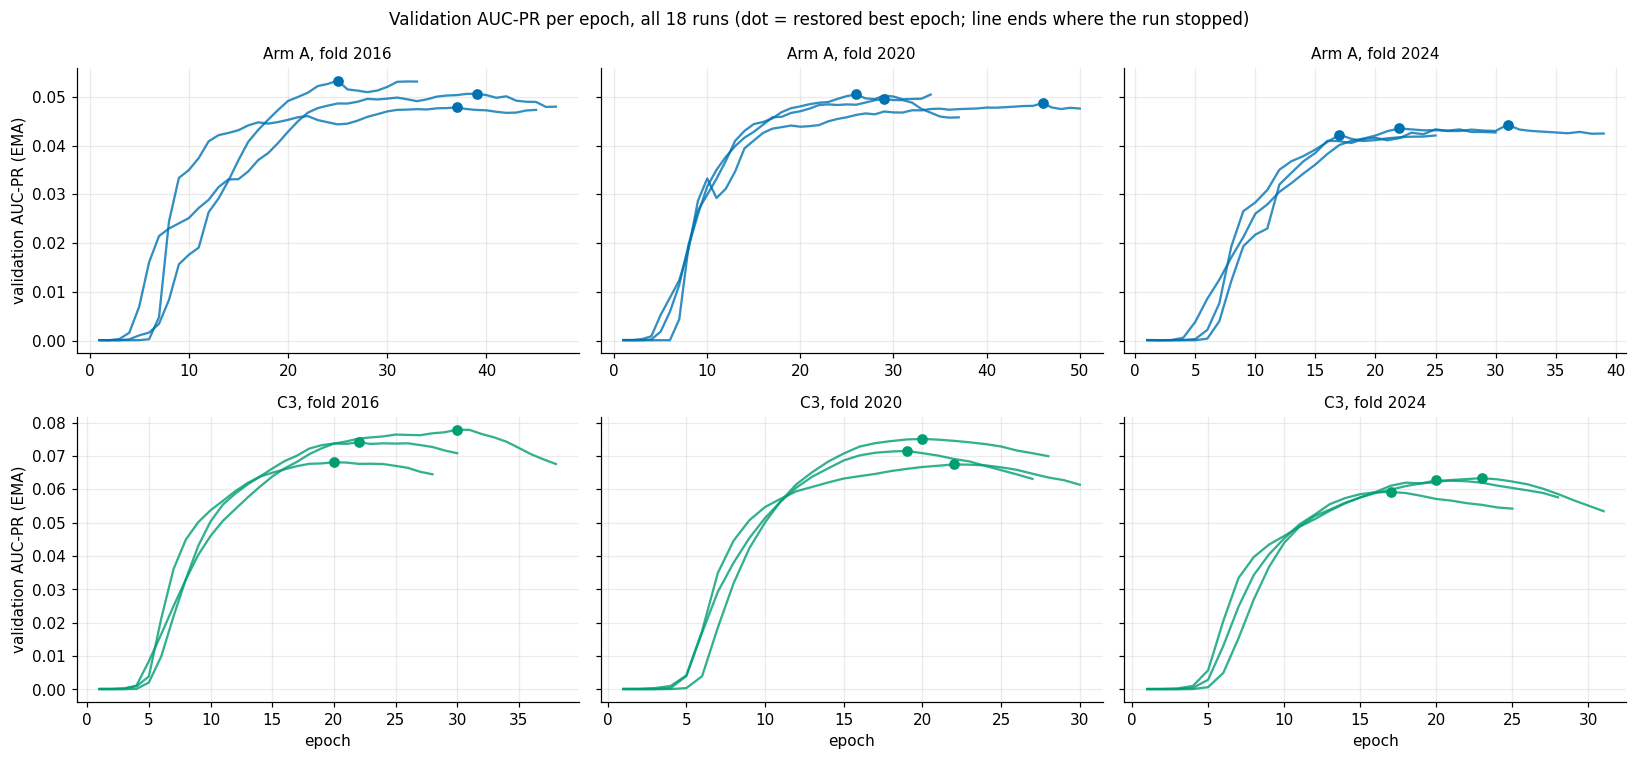

seed 10 fold 2016: A best 39 stopped 47 (early) | C3 best 20 stopped 28 (early)
seed 10 fold 2020: A best 46 stopped 50 (ran to cap) | C3 best 22 stopped 30 (early)
seed 10 fold 2024: A best 17 stopped 25 (early) | C3 best 20 stopped 28 (early)
seed 11 fold 2016: A best 25 stopped 33 (early) | C3 best 30 stopped 38 (early)
seed 11 fold 2020: A best 26 stopped 34 (early) | C3 best 19 stopped 27 (early)
seed 11 fold 2024: A best 22 stopped 30 (early) | C3 best 17 stopped 25 (early)
seed 12 fold 2016: A best 37 stopped 45 (early) | C3 best 22 stopped 30 (early)
seed 12 fold 2020: A best 29 stopped 37 (early) | C3 best 20 stopped 28 (early)
seed 12 fold 2024: A best 31 stopped 39 (early) | C3 best 23 stopped 31 (early)
median best epoch: A 29, C3 20


In [16]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for j, f in enumerate(FOLDS):
    for s in SEEDS:
        ha = [m["auc_pr"] for m in find(ES_A[s][j], "early_stopping")["history"]]
        hc = [m["auc_pr"] for m in find(ES_C[(s, f)], "early_stopping")["history"]]
        ba = find(ES_A[s][j], "early_stopping")["best_epoch"]; bc = find(ES_C[(s, f)], "early_stopping")["best_epoch"]
        ax[0, j].plot(range(1, len(ha) + 1), ha, color=COL["A"], alpha=0.8); ax[0, j].plot(ba, ha[ba - 1], "o", color=COL["A"])
        ax[1, j].plot(range(1, len(hc) + 1), hc, color=COL["C3"], alpha=0.8); ax[1, j].plot(bc, hc[bc - 1], "o", color=COL["C3"])
    ax[0, j].set_title(f"Arm A, fold {f}", fontsize=10); ax[1, j].set_title(f"C3, fold {f}", fontsize=10); ax[1, j].set_xlabel("epoch")
ax[0, 0].set_ylabel("validation AUC-PR (EMA)"); ax[1, 0].set_ylabel("validation AUC-PR (EMA)")
plt.suptitle("Validation AUC-PR per epoch, all 18 runs (dot = restored best epoch; line ends where the run stopped)", fontsize=11)
plt.tight_layout(); plt.show()
ba_, bc_ = [], []
for s in SEEDS:
    for j, f in enumerate(FOLDS):
        ea, ec = find(ES_A[s][j], "early_stopping"), find(ES_C[(s, f)], "early_stopping")
        ba_.append(ea["best_epoch"]); bc_.append(ec["best_epoch"])
        print(f"seed {s} fold {f}: A best {ea['best_epoch']:2d} stopped {ea['stopped_epoch']:2d} ({'early' if ea['stopped_early'] else 'ran to cap'}) | C3 best {ec['best_epoch']:2d} stopped {ec['stopped_epoch']:2d} ({'early' if ec['stopped_early'] else 'ran to cap'})")
print(f"median best epoch: A {np.median(ba_):.0f}, C3 {np.median(bc_):.0f}")

**What it shows.** With the same fair stopping rule, the repaired ConvLSTM **beats** arm A: pooled **+29.4%** (+35.8 / +5.7 / +46.7%), positive in all three folds, with the paired interval excluding zero in 2016 and 2024 (2020's includes zero), so the pre-registered verdict is **helps, confirmed**. The earlier "no detectable effect" for C3 (-1.5%) and C3 + dropout (+1.9%) compared a model that overfits after epoch ~20 with an arm that does not.
C3 stopped early in all nine runs (best epochs 17-30, median 20); arm A in eight of nine (best epochs 17-46, median 29, a nearly flat curve so its best epoch is noisy). Early-stopped C3 singles beat their own 50-epoch versions in 9 of 9 runs, and the ensemble gain over a single model is now similar for both arms, so the earlier "weak but diverse members" story was the overfit tail.
The timing metric (false alarms on quiet bins of severe days at 50% recall) is 54-71% lower than A's, and best-F1 is higher in all folds. **Not shown:** that recurrence is the cause. C3 bundles GroupNorm, pooled skips, clipping, lr 1e-4 and the LSTM, and the no-recurrence ablation has not been run under this stopping rule. About 12% is resolvable with 3 seeds, and fold 2020 is inside the noise. Full scoring of the eight predictions: `docs/convlstm_early_stopping_results.md`.

## 6c. Chapter 7: a tuned arm-A control

The +29.4% compared C3 (lr 1e-4, clip 1.0, tuned partly on fold 2020) with arm A at its original, never-tuned recipe (lr 1e-3, no clip). Pre-registered control (`docs/unet_control_preregistration.md`): **Stage 1** picks an optimizer setting for arm A on fold 2018 (outside the study folds, seeds 20/21), accepting a non-default only if it is at least 5% above the default; **Stage 2** reruns arm A with the selected setting on the study folds and scores it against the same early-stopped C3 models. Numbers: `models/unet_control/`.

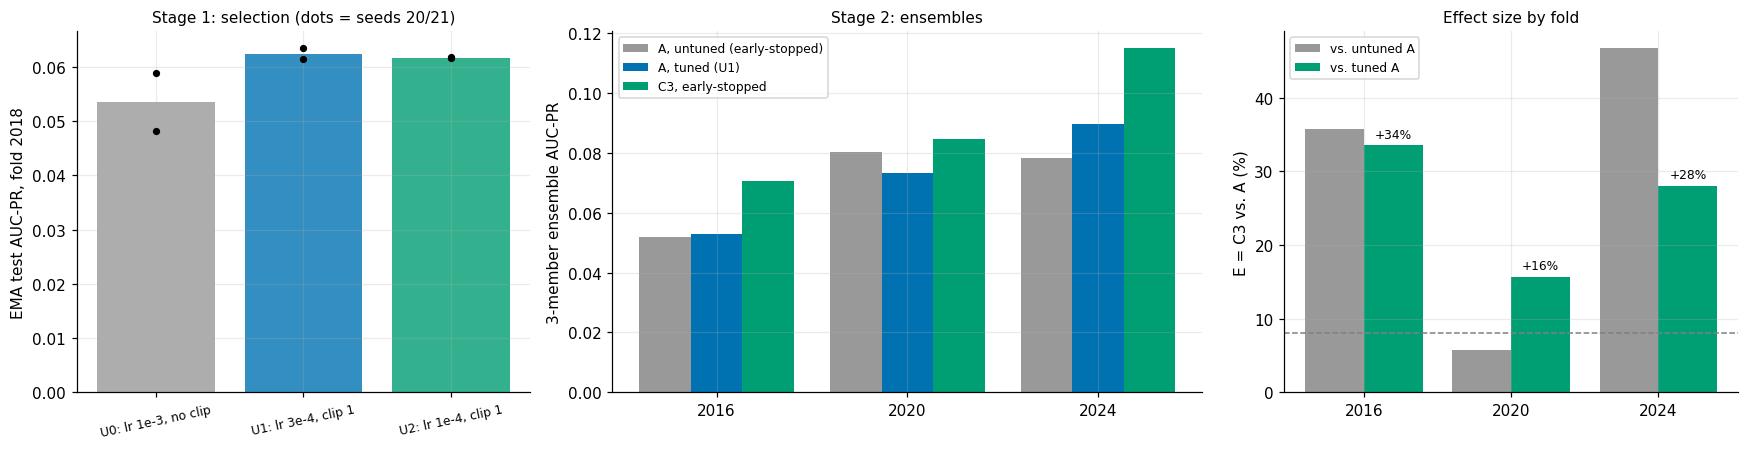

Stage 1 selected U1 (+16.6% vs. U0)
Stage 2 verdict: helps | pooled E +25.8% | folds positive 3/3 | paired interval excludes 0 in 3 | confirmed=True
tuned-A vs untuned-A ensembles: ['+1.7%', '-8.6%', '+14.6%']


In [17]:
UC = M / "unet_control"
sel = load(UC / "select/selection.json")
ctl = load(UC / "tuned_a/convlstm_eval.json")
names = {"U0": "U0: lr 1e-3, no clip", "U1": "U1: lr 3e-4, clip 1", "U2": "U2: lr 1e-4, clip 1"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1.3, 1]})
for i, (k, r) in enumerate(sel["rows"].items()):
    ax[0].bar(i, r["mean_auc_pr"], color=[COL["baseline"], COL["A"], COL["C3"]][i], alpha=0.8)
    ax[0].scatter([i, i], r["auc_pr"], color="black", zorder=3, s=14)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels([names[k] for k in sel["rows"]], fontsize=8, rotation=12)
ax[0].set_ylabel("EMA test AUC-PR, fold 2018"); ax[0].set_title("Stage 1: selection (dots = seeds 20/21)", fontsize=10)
rows2 = ctl["folds"]; x = np.arange(3); w = 0.27
old_es_a = [r["a_ens_ap"] for r in es_eval["folds"]]
ax[1].bar(x - w, old_es_a, w, color=COL["baseline"], label="A, untuned (early-stopped)")
ax[1].bar(x, [r["a_ens_ap"] for r in rows2], w, color=COL["A"], label="A, tuned (U1)")
ax[1].bar(x + w, [r["convlstm_ens_ap"] for r in rows2], w, color=COL["C3"], label="C3, early-stopped")
ax[1].set_xticks(x); ax[1].set_xticklabels(FOLDS); ax[1].set_ylabel("3-member ensemble AUC-PR"); ax[1].legend(fontsize=8); ax[1].set_title("Stage 2: ensembles", fontsize=10)
ax[2].bar(x - 0.2, [100 * r["E"] for r in es_eval["folds"]], 0.4, color=COL["baseline"], label="vs. untuned A")
ax[2].bar(x + 0.2, [100 * r["E"] for r in rows2], 0.4, color=COL["C3"], label="vs. tuned A")
for i, r in enumerate(rows2):
    ax[2].text(i + 0.2, 100 * r["E"] + 1, f"{100 * r['E']:+.0f}%", ha="center", fontsize=8)
ax[2].axhline(8, color="grey", ls="--", lw=1)
ax[2].set_xticks(x); ax[2].set_xticklabels(FOLDS); ax[2].set_ylabel("E = C3 vs. A (%)"); ax[2].legend(fontsize=8); ax[2].set_title("Effect size by fold", fontsize=10)
plt.tight_layout(); plt.show()
sm = ctl["summary"]
print(f"Stage 1 selected {sel['selected']} (+{100 * (sel['rows']['U1']['mean_auc_pr'] / sel['rows']['U0']['mean_auc_pr'] - 1):.1f}% vs. U0)")
print(f"Stage 2 verdict: {sm['verdict']} | pooled E {100 * sm['pooled_E']:+.1f}% | folds positive {sm['folds_positive']}/3 | paired interval excludes 0 in {sm['folds_paired_ci_excludes_zero']} | confirmed={sm['confirmed']}")
print("tuned-A vs untuned-A ensembles:", [f"{100 * (a['a_ens_ap'] / b - 1):+.1f}%" for a, b in zip(rows2, old_es_a)])

**What it shows.** Tuning helped arm A on the selection fold (+16.6% for lr 3e-4 with clipping; lr 1e-4 was tied at +15.2%), but on the study folds the effect on arm A is small (ensembles +1.7 / -8.6 / +14.6%, pooled +2.6%, inside the noise). Against the tuned arm A the ConvLSTM still wins: pooled **+25.8%** (+33.5 / +15.7 / +28.1%), positive in all three folds, with the paired interval excluding 0 in all three (2020's only narrowly), so the pre-registered verdict is **helps, confirmed**. About 88% of the earlier +29.4% survives, so the gap is not mainly an optimizer-recipe artifact.
The timing metric stays 45-72% lower than A's, and tuning did not change A's own timing numbers. **Not shown:** that recurrence is the cause. C3 also carries GroupNorm and pooled skips, which the U-Net does not (a GroupNorm U-Net control was not run), and C3's own lr was not re-tuned. Full scoring: `docs/unet_control_results.md`.

## 8. What this study shows, and what it does not

**Shown.**
* A ConvLSTM-U-Net fed the raw hourly sequence **hurt** (-19.7%) in its first form, and the cause was diagnosable: saturated LSTM gates from un-normalized inputs.
* Once repaired, it **ties** arm A's hand-built time pooling (pooled -1.5%, every paired interval includes zero; resolution ~12%). The hand-built pooling was not beaten by a learned recurrence.
* It improves the *timing* problem substantially (false alarms on quiet bins of severe days down 45-63%) while giving up cell-level separation.
* It overfits (val/train loss 2.3-4.3x), and its single models are 24-31% weaker than A's; the ensemble tie comes from diversity.

**Not shown.**
* That recurrence matters. The no-recurrence ablation matched the recurrent model in the ladder (one seed, 10 epochs); the repair changed GroupNorm, skips, clipping and learning rate together.
* That the tie is equivalence. With 3 seeds the study cannot see differences under ~12%.
* Anything about deployment: production serving is untouched.

* **Dropout (Stage 2):** p=0.1 gives pooled E +1.9% vs. arm A (+1.7 / +1.2 / +2.7%), every paired interval includes 0: **no detectable effect**. It lowered the overfitting ratio only modestly (mean 3.16 -> 2.68, lower in all nine pairs, still ~4x arm A's) and left single models 22-27% weaker than A's. Whether dropout beats no-dropout C3 (+3.4 points pooled) is not resolvable with 3 seeds.

Predictions scored in `docs/convlstm_dropout_results.md`: the verdict category and central guess were close (my 60% "no detectable effect", central +3% vs. +1.9% observed); the claims that dropout would fix single-model strength, shrink the ensemble gain, or bring the ratio into the healthy band all missed.

**Per-epoch rerun (one fold, one seed):** the ConvLSTM's held-out AUC-PR peaks around epoch 15-20 and falls to about half by epoch 50 (arm A's holds within ~8% of its peak), so the 50-epoch comparison favored A; early stopping on a separate validation set is the next study.

**Early stopping for both arms (Chapter 6):** pooled E **+29.4%** for the early-stopped repaired ConvLSTM vs. early-stopped arm A (+35.8 / +5.7 / +46.7%), interval excludes 0 in 2016 and 2024: **helps, confirmed**. This supersedes the reading of the 50-epoch studies above (-1.5% and +1.9%), which compared an overfit model with a non-overfitting arm. Whether recurrence is what matters is still untested.

**Tuned arm-A control (Chapter 7):** with arm A tuned over lr and clipping (selected on fold 2018, lr 3e-4 + clip 1.0), the ConvLSTM still leads by a pooled **+25.8%** (+33.5 / +15.7 / +28.1%), paired intervals exclude 0 in all three folds: **helps, confirmed**. Tuning moved arm A's ensembles by only +2.6% pooled; about 88% of the +29.4% survives. Still untested: that recurrence (rather than GroupNorm, pooled skips or C3's own tuning) is the cause.

**Next-step options:** a 3-seed no-recurrence ablation under the same stopping rule (the open question about whether the LSTM matters); a hybrid that feeds arm A's pooled fields to the decoder; a 12-fold confirmation of early-stopped C3 vs. A; or a serving path for hourly features (live pulls of fxx 0-7 plus a retrained bundle).